# Bài 1. Phân tích và phân đoạn ảnh màu

**Nội dung:** (1) chuyển RGB → HSV / HSI / CIELAB và hiển thị từng kênh; (2) phân đoạn 2 nhóm đối tượng theo màu và
so sánh kết quả khi đặt ngưỡng trong RGB với HSV / HSI; (3) khảo sát 3 bộ tham số ngưỡng.

**Ảnh đầu vào (2 ảnh màu, thu nhỏ cạnh dài còn 400 px):**
* `coffee.png` - tách *sứ đỏ (cốc, đĩa)* và *mặt bàn gỗ* (hai màu cùng họ đỏ-cam nhưng khác sắc độ).
* `astronaut.png` - tách *bộ đồ phi hành gia màu cam* và *nền trắng/xám* (khác về độ bão hòa).

In [1]:
# ===== Cài đặt & hàm tiện ích dùng chung =====
import os, time, warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color, filters, morphology, measure, segmentation, util
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "font.size": 9, "axes.titlesize": 9})

# Thư mục ảnh đầu vào / kết quả.
# Muốn dùng ảnh trong bộ dữ liệu LMS: chép ảnh vào images/ và đổi tên file ở ô "Ảnh đầu vào".
IMG_DIR, OUT_DIR = "images", "outputs/bai1"
for d in (IMG_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)


def load_rgb(name, fallback, max_side=None):
    """Đọc ảnh màu RGB từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, cv2.cvtColor(fallback(), cv2.COLOR_RGB2BGR))
    img = cv2.cvtColor(cv2.imread(p, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    if max_side and max(img.shape[:2]) > max_side:
        s = max_side / max(img.shape[:2])
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def load_gray(name, fallback, max_side=None):
    """Đọc ảnh xám uint8 từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, fallback())
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if max_side and max(img.shape) > max_side:
        s = max_side / max(img.shape)
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def show(images, titles=None, ncols=4, name=None, cell=3.0, cmap="gray"):
    """Hiển thị lưới ảnh; ảnh 2-D hiển thị theo thang xám cố định; lưu vào OUT_DIR/name."""
    n = len(images)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(cell * ncols, (cell * images[0].shape[0] / images[0].shape[1] + 0.35) * nrows), squeeze=False)
    for i, ax in enumerate(axs.ravel()):
        ax.axis("off")
        if i >= n:
            continue
        im = images[i]
        if im.ndim == 2:
            if im.dtype == np.uint8:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=255)
            elif im.dtype == bool:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=1)
            else:
                ax.imshow(im, cmap=cmap)
        else:
            ax.imshow(im)
        if titles is not None:
            ax.set_title(titles[i])
    fig.tight_layout()
    if name:
        fig.savefig(os.path.join(OUT_DIR, name), dpi=110, bbox_inches="tight")
    plt.show()


## 1.0 Ảnh đầu vào

coffee: (267, 400, 3) | astronaut: (400, 400, 3)


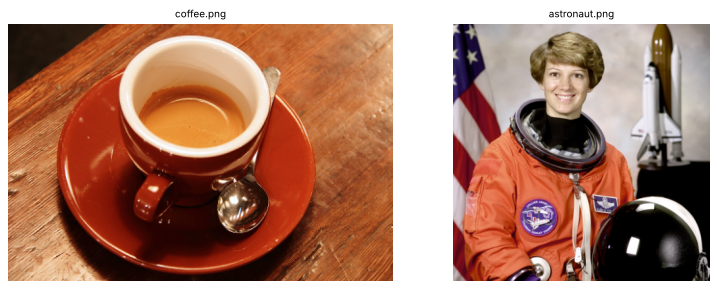

In [2]:
coffee = load_rgb("coffee.png", data.coffee, max_side=400)
astro = load_rgb("astronaut.png", data.astronaut, max_side=400)
print("coffee:", coffee.shape, "| astronaut:", astro.shape)
show([coffee, astro], ["coffee.png", "astronaut.png"], ncols=2, cell=5, name="b1_input.png")

## 1.1 Chuyển đổi không gian màu và hiển thị các kênh

* **HSV:** `cv2.cvtColor(..., COLOR_RGB2HSV)` trên ảnh float32 (H ∈ [0,360), S, V ∈ [0,1]).
* **HSI (tự cài đặt):** $I=\frac{R+G+B}{3}$, $S=1-\frac{3\min(R,G,B)}{R+G+B}$,
  $H=\theta$ nếu $B\le G$, ngược lại $360^\circ-\theta$, với $\theta=\arccos\left(\frac{\frac12[(R-G)+(R-B)]}{\sqrt{(R-G)^2+(R-B)(G-B)}}\right)$.
* **CIELAB:** `skimage.color.rgb2lab` (nguồn sáng D65): L ∈ [0,100], a*, b* ∈ ≈[-128,127].

Kênh Hue được hiển thị bằng bảng màu cầu vồng (S = V = 1) để dễ quan sát; các kênh còn lại là ảnh xám.

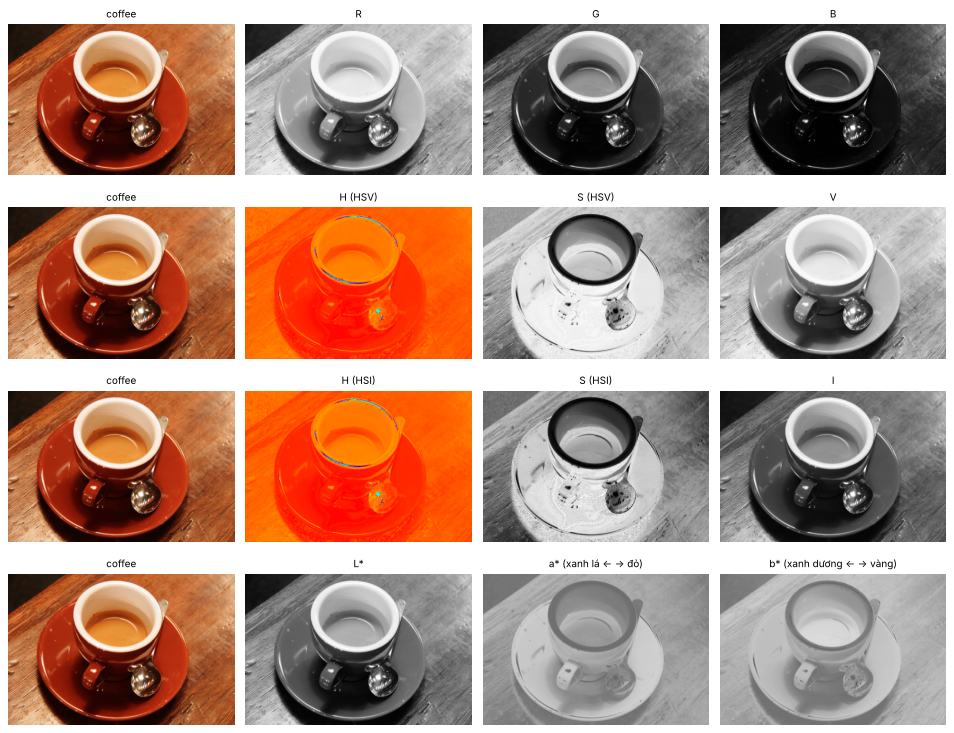

In [3]:
def rgb2hsv_f(rgb):
    """RGB uint8 -> H (độ, 0-360), S, V (0-1) dùng OpenCV."""
    hsv = cv2.cvtColor(rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2HSV)
    return hsv[..., 0], hsv[..., 1], hsv[..., 2]


def rgb2hsi(rgb):
    """RGB uint8 -> H (độ, 0-360), S, I (0-1) theo công thức giáo trình."""
    f = rgb.astype(np.float64) / 255.0
    R, G, B = f[..., 0], f[..., 1], f[..., 2]
    eps = 1e-10
    I = (R + G + B) / 3.0
    S = 1.0 - 3.0 * np.minimum(np.minimum(R, G), B) / (R + G + B + eps)
    num = 0.5 * ((R - G) + (R - B))
    den = np.sqrt((R - G) ** 2 + (R - B) * (G - B)) + eps
    theta = np.degrees(np.arccos(np.clip(num / den, -1.0, 1.0)))
    H = np.where(B <= G, theta, 360.0 - theta)
    H = np.where(S < 1e-6, 0.0, H)                      # xám: Hue không xác định
    return H, S, I


def hue_rgb(H):
    """Ảnh màu thể hiện Hue (S = V = 1)."""
    return (color.hsv2rgb(np.dstack([H / 360.0, np.ones_like(H), np.ones_like(H)])) * 255).astype(np.uint8)


def to_u8(x, lo=0.0, hi=1.0):
    return np.clip((x - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)


def channels_figure(rgb, name, fname):
    Hv, Sv, Vv = rgb2hsv_f(rgb)
    Hi, Si, Ii = rgb2hsi(rgb)
    L, a, b = [c for c in np.moveaxis(color.rgb2lab(rgb), -1, 0)]
    imgs = [rgb, rgb[..., 0], rgb[..., 1], rgb[..., 2],
            rgb, hue_rgb(Hv), to_u8(Sv), to_u8(Vv),
            rgb, hue_rgb(Hi), to_u8(Si), to_u8(Ii),
            rgb, to_u8(L, 0, 100), to_u8(a, -60, 80), to_u8(b, -60, 80)]
    tits = [f"{name}", "R", "G", "B",
            f"{name}", "H (HSV)", "S (HSV)", "V",
            f"{name}", "H (HSI)", "S (HSI)", "I",
            f"{name}", "L*", "a* (xanh lá ← → đỏ)", "b* (xanh dương ← → vàng)"]
    show(imgs, tits, ncols=4, cell=3.0, name=fname)
    return (Hv, Sv, Vv), (Hi, Si, Ii), (L, a, b)

hsv_c, hsi_c, lab_c = channels_figure(coffee, "coffee", "b1_channels_coffee.png")

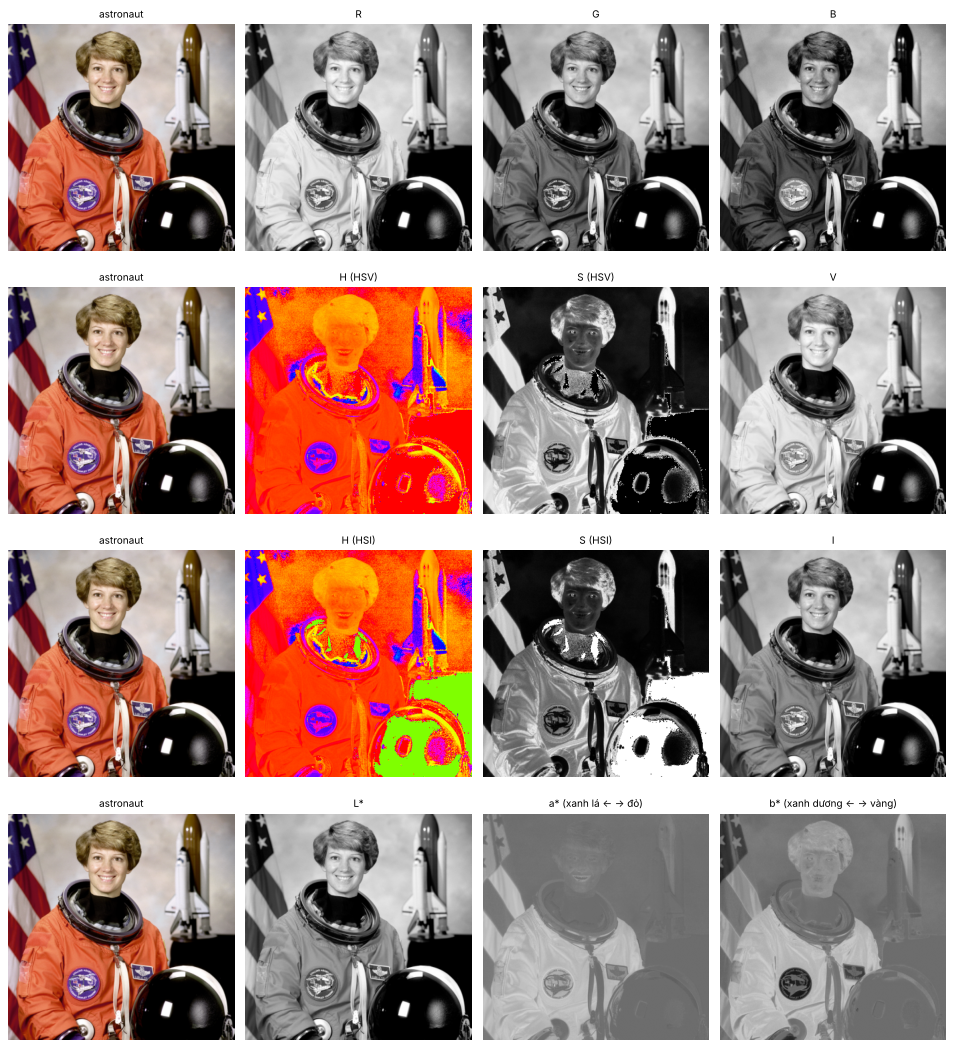

In [4]:
hsv_a, hsi_a, lab_a = channels_figure(astro, "astronaut", "b1_channels_astronaut.png")

In [5]:
# kiểm chứng cài đặt HSI tự viết: các cạnh/giá trị đặc biệt và so với HSV
t = np.array([[[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 255], [128, 128, 128], [255, 128, 0]]], np.uint8)
H, S, I = rgb2hsi(t)
Hh, Sh, Vh = rgb2hsv_f(t)
print("điểm màu:        đỏ      lục    lam   trắng   xám   cam")
print("H (HSI)   :", np.round(H[0], 1))
print("H (HSV)   :", np.round(Hh[0], 1))
print("S (HSI)   :", np.round(S[0], 2))
print("S (HSV)   :", np.round(Sh[0], 2))
print("I / V     :", np.round(I[0], 2), "/", np.round(Vh[0], 2))
print("Khác biệt Hue HSV - HSI trung bình (độ) trên coffee: %.2f; trên astronaut: %.2f" %
      (np.abs(hsv_c[0] - hsi_c[0]).mean(), np.abs(hsv_a[0] - hsi_a[0]).mean()))

điểm màu:        đỏ      lục    lam   trắng   xám   cam
H (HSI)   : [  0.  120.  240.    0.    0.   30.1]
H (HSV)   : [  0.  120.  240.    0.    0.   30.1]
S (HSI)   : [1. 1. 1. 0. 0. 1.]
S (HSV)   : [1. 1. 1. 0. 0. 1.]
I / V     : [0.33 0.33 0.33 1.   0.5  0.5 ] / [1.  1.  1.  1.  0.5 1. ]
Khác biệt Hue HSV - HSI trung bình (độ) trên coffee: 0.69; trên astronaut: 10.07


**Nhận xét 1.1**
* **RGB** trộn lẫn màu và độ sáng: ở `coffee`, kênh R đều cao ở cả đĩa đỏ sáng lẫn mặt bàn gỗ, nên từng kênh R/G/B riêng lẻ khó dùng để phân biệt hai vật.
* **HSV/HSI** tách màu (Hue) khỏi sáng tối (V/I): ở `coffee`, Hue của sứ đỏ ≈ 10° còn gỗ ≈ 22–30°, nhìn kênh H đã phân biệt rõ; kênh S thấp ở vùng trắng/xám (nền, vành cốc, tàu con thoi) và cao ở bộ đồ cam. Kênh H **nhiễu mạnh ở vùng gần đen hoặc gần xám** (mũ bảo hiểm đen, nền xám) vì Hue không xác định khi S ≈ 0 hoặc V ≈ 0 -> khi phân đoạn phải kèm điều kiện trên S và V.
* **HSI vs HSV:** hàm tự cài đặt cho đúng các giá trị đặc biệt (đỏ/lục/lam/trắng/xám/cam đều khớp công thức; Hue cam = 30.1° ở cả hai). Hue của HSV và HSI gần như trùng trên `coffee` (lệch TB 0,69°) nhưng lệch TB 10,07° trên `astronaut` chủ yếu ở vùng tối/xám (mũ bảo hiểm hiện màu xanh lá ở kênh H của HSI). $S_{HSI}$ nhỏ hơn $S_{HSV}$ (màu cam (214,99,63): 0,50 so với 0,71) và $I$ (trung bình) tối hơn $V$ (max).
* **CIELAB:** L* là độ sáng cảm nhận; a* cao (đỏ) ở bộ đồ cam/sứ đỏ, b* cao (vàng) ở gỗ và tóc. Biên độ a*, b* nhỏ nên phải kéo giãn tương phản khi hiển thị. Khoảng cách Euclid trong Lab gần với cảm nhận màu nên được dùng ở Bài 4 (region growing, K-means).

## 1.2 Phân đoạn 2 nhóm đối tượng theo màu: RGB so với HSV / HSI

Mỗi nhóm được mô tả bằng một "hộp" ngưỡng trong từng không gian màu:
* **RGB:** `lo ≤ R,G,B ≤ hi` cho từng kênh (+ điều kiện chênh lệch kênh nếu cần).
* **HSV:** khoảng Hue `[h0, h1]` (xử lý vòng 360°), `S ≥ s_min`, `V ≥ v_min` (hoặc `S ≤ s_max` cho màu xám/trắng).
* **HSI:** tương tự HSV nhưng với `I` thay `V` và `S` theo công thức HSI. Lưu ý $S_{HSI}$ thường *nhỏ hơn* $S_{HSV}$ và $I\le V$ nên ngưỡng `s_min`, `v_min` phải hạ thấp tương ứng.

Mặt nạ được làm sạch bằng opening (ellipse 3×3) để loại điểm nhiễu rời rạc.

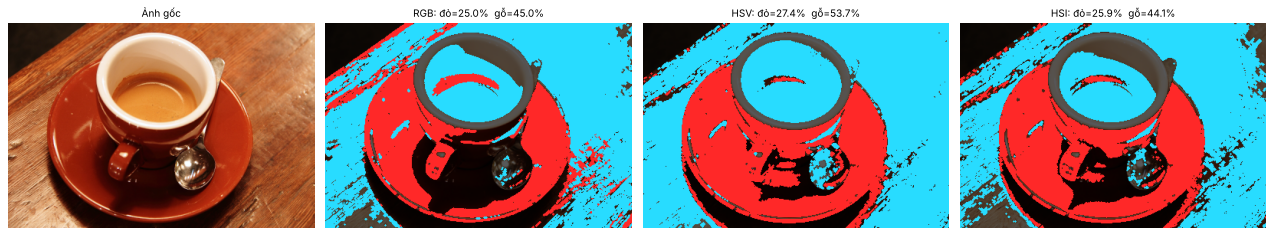

Chú thích màu: ĐỎ = sứ đỏ, XANH LƠ = mặt bàn gỗ (nhóm còn lại tối đi).
IoU giữa các không gian màu (nhóm sứ đỏ): {'RGB-HSV': np.float64(0.591), 'HSV-HSI': np.float64(0.885), 'RGB-HSI': np.float64(0.648)}
IoU giữa các không gian màu (nhóm gỗ)   : {'RGB-HSV': np.float64(0.826), 'HSV-HSI': np.float64(0.821), 'RGB-HSI': np.float64(0.869)}


In [6]:
def hue_in(H, h0, h1):
    return (H >= h0) & (H <= h1) if h0 <= h1 else (H >= h0) | (H <= h1)

def clean(m, k=3):
    return cv2.morphologyEx(m.astype(np.uint8), cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))) > 0

def m_rgb(rgb, rlo=0, rhi=255, glo=0, ghi=255, blo=0, bhi=255, rg_diff=None, spread=None):
    R, G, B = [rgb[..., i].astype(int) for i in range(3)]
    m = (R >= rlo) & (R <= rhi) & (G >= glo) & (G <= ghi) & (B >= blo) & (B <= bhi)
    if rg_diff is not None:
        m &= (R - G) >= rg_diff
    if spread is not None:                                 # max - min kênh <= spread (gần xám)
        m &= (rgb.max(-1).astype(int) - rgb.min(-1).astype(int)) <= spread
    return clean(m)

def m_hs(H, S, V, h0=0, h1=360, smin=0.0, smax=1.0, vmin=0.0, vmax=1.0):
    return clean(hue_in(H, h0, h1) & (S >= smin) & (S <= smax) & (V >= vmin) & (V <= vmax))

def paint(rgb, masks, colors):
    o = (rgb * 0.35).astype(np.uint8)
    for m, c in zip(masks, colors):
        o[m] = c
    return o

def iou(a, b):
    return (a & b).sum() / max((a | b).sum(), 1)

# --- ảnh coffee: nhóm 1 = sứ đỏ, nhóm 2 = mặt bàn gỗ ---
Hv, Sv, Vv = hsv_c; Hi, Si, Ii = hsi_c
coffee_masks = {
    "RGB": (m_rgb(coffee, rlo=90, glo=0, ghi=75, bhi=70, rg_diff=60),                 # đỏ đậm: R cao, G/B thấp
            m_rgb(coffee, rlo=140, glo=70, ghi=200, bhi=130, rg_diff=30)),           # nâu cam sáng
    "HSV": (m_hs(Hv, Sv, Vv, 0, 16, smin=0.6, vmin=0.15),
            m_hs(Hv, Sv, Vv, 17, 40, smin=0.3, vmin=0.3)),
    "HSI": (m_hs(Hi, Si, Ii, 0, 16, smin=0.6, vmin=0.07),
            m_hs(Hi, Si, Ii, 17, 40, smin=0.3, vmin=0.25)),
}
imgs, tits = [coffee], ["Ảnh gốc"]
for k, (m1, m2) in coffee_masks.items():
    imgs.append(paint(coffee, [m1, m2], [(255, 40, 40), (40, 220, 255)]))
    tits.append(f"{k}: đỏ={100 * m1.mean():.1f}%  gỗ={100 * m2.mean():.1f}%")
show(imgs, tits, ncols=4, cell=4.0, name="b1_seg_coffee.png")
print("Chú thích màu: ĐỎ = sứ đỏ, XANH LƠ = mặt bàn gỗ (nhóm còn lại tối đi).")
print("IoU giữa các không gian màu (nhóm sứ đỏ):", {f"{a}-{b}": round(iou(coffee_masks[a][0], coffee_masks[b][0]), 3) for a, b in [("RGB", "HSV"), ("HSV", "HSI"), ("RGB", "HSI")]})
print("IoU giữa các không gian màu (nhóm gỗ)   :", {f"{a}-{b}": round(iou(coffee_masks[a][1], coffee_masks[b][1]), 3) for a, b in [("RGB", "HSV"), ("HSV", "HSI"), ("RGB", "HSI")]})

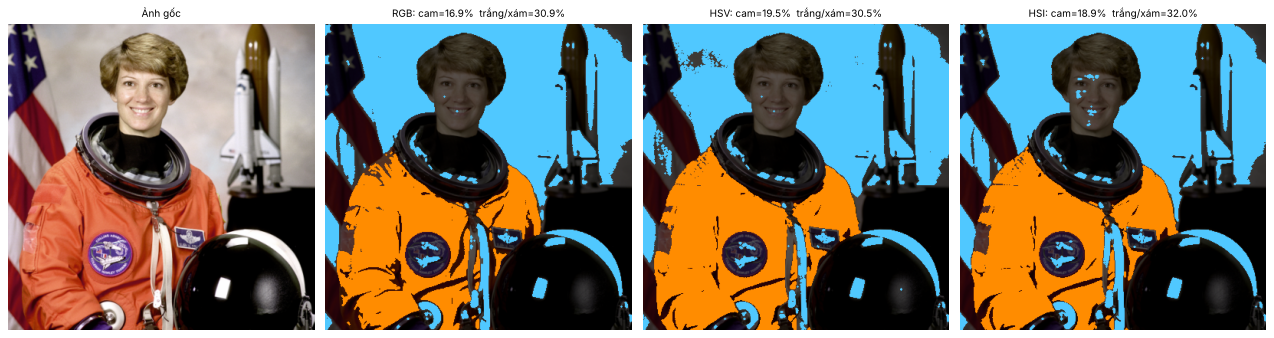

Chú thích màu: CAM = bộ đồ, XANH NHẠT = nền trắng/xám (nhóm còn lại tối đi).
IoU (nhóm bộ đồ cam): {'RGB-HSV': np.float64(0.854), 'HSV-HSI': np.float64(0.967), 'RGB-HSI': np.float64(0.878)}
IoU (nhóm nền trắng): {'RGB-HSV': np.float64(0.932), 'HSV-HSI': np.float64(0.917), 'RGB-HSI': np.float64(0.961)}


In [7]:
# --- ảnh astronaut: nhóm 1 = bộ đồ cam, nhóm 2 = nền trắng/xám ---
Hv, Sv, Vv = hsv_a; Hi, Si, Ii = hsi_a
astro_masks = {
    "RGB": (m_rgb(astro, rlo=170, glo=50, ghi=140, bhi=110, rg_diff=70),
            m_rgb(astro, rlo=150, glo=150, blo=150, spread=30)),
    "HSV": (m_hs(Hv, Sv, Vv, 5, 25, smin=0.55, vmin=0.4),
            m_hs(Hv, Sv, Vv, smax=0.12, vmin=0.6)),
    "HSI": (m_hs(Hi, Si, Ii, 5, 25, smin=0.35, vmin=0.25),
            m_hs(Hi, Si, Ii, smax=0.1, vmin=0.6)),
}
imgs, tits = [astro], ["Ảnh gốc"]
for k, (m1, m2) in astro_masks.items():
    imgs.append(paint(astro, [m1, m2], [(255, 140, 0), (80, 200, 255)]))
    tits.append(f"{k}: cam={100 * m1.mean():.1f}%  trắng/xám={100 * m2.mean():.1f}%")
show(imgs, tits, ncols=4, cell=4.0, name="b1_seg_astronaut.png")
print("Chú thích màu: CAM = bộ đồ, XANH NHẠT = nền trắng/xám (nhóm còn lại tối đi).")
print("IoU (nhóm bộ đồ cam):", {f"{a}-{b}": round(iou(astro_masks[a][0], astro_masks[b][0]), 3) for a, b in [("RGB", "HSV"), ("HSV", "HSI"), ("RGB", "HSI")]})
print("IoU (nhóm nền trắng):", {f"{a}-{b}": round(iou(astro_masks[a][1], astro_masks[b][1]), 3) for a, b in [("RGB", "HSV"), ("HSV", "HSI"), ("RGB", "HSI")]})

### So sánh độ bền vững với thay đổi chiếu sáng
Giả lập ảnh tối hơn (nhân cường độ RGB × 0.6) và sáng hơn/lệch (gamma 0.7) rồi áp **đúng các ngưỡng cũ**.
Với mỗi không gian màu, đo IoU giữa mặt nạ trên ảnh đã đổi sáng và mặt nạ trên ảnh gốc (1.0 = không đổi).
Ngưỡng nằm trên kênh sắc độ (H, S) kỳ vọng ít bị ảnh hưởng hơn so với ngưỡng thẳng trên R, G, B.

ảnh / nhóm                 biến đổi         RGB     HSV     HSI   (IoU so với kết quả trên ảnh gốc)
coffee / sứ đỏ             tối x0.6       0.512   0.822   0.825
coffee / gỗ                tối x0.6       0.028   0.971   0.607
coffee / sứ đỏ             gamma 0.7      0.452   0.728   0.639
coffee / gỗ                gamma 0.7      0.636   0.862   0.689
astro / bộ đồ cam          tối x0.6       0.000   0.889   0.736
astro / nền trắng          tối x0.6       0.022   0.000   0.000
astro / bộ đồ cam          gamma 0.7      0.565   0.594   0.523
astro / nền trắng          gamma 0.7      0.876   0.860   0.870


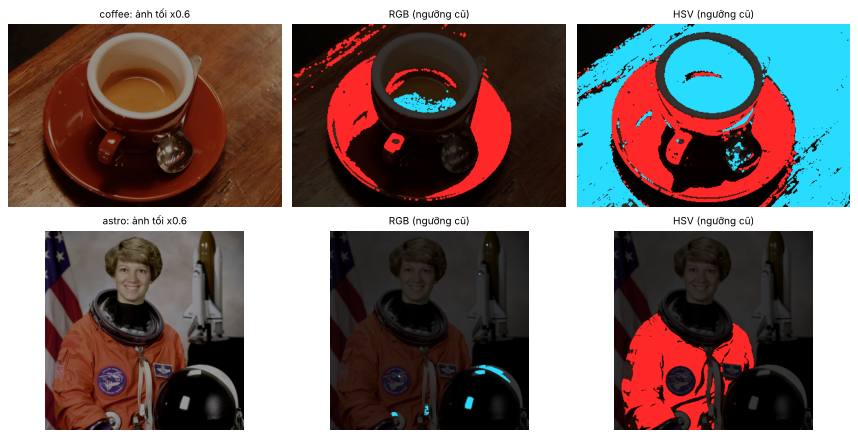

In [8]:
def seg_all(rgb, which):
    """Chạy lại ba bộ luật ngưỡng ở trên cho ảnh rgb (which: 'coffee' | 'astro')."""
    hv, hi = rgb2hsv_f(rgb), rgb2hsi(rgb)
    if which == "coffee":
        return {"RGB": (m_rgb(rgb, rlo=90, glo=0, ghi=75, bhi=70, rg_diff=60), m_rgb(rgb, rlo=140, glo=70, ghi=200, bhi=130, rg_diff=30)),
                "HSV": (m_hs(*hv, 0, 16, smin=0.6, vmin=0.15), m_hs(*hv, 17, 40, smin=0.3, vmin=0.3)),
                "HSI": (m_hs(*hi, 0, 16, smin=0.6, vmin=0.07), m_hs(*hi, 17, 40, smin=0.3, vmin=0.25))}
    return {"RGB": (m_rgb(rgb, rlo=170, glo=50, ghi=140, bhi=110, rg_diff=70), m_rgb(rgb, rlo=150, glo=150, blo=150, spread=30)),
            "HSV": (m_hs(*hv, 5, 25, smin=0.55, vmin=0.4), m_hs(*hv, smax=0.12, vmin=0.6)),
            "HSI": (m_hs(*hi, 5, 25, smin=0.35, vmin=0.25), m_hs(*hi, smax=0.1, vmin=0.6))}

def darker(rgb):
    return (rgb.astype(np.float32) * 0.6).astype(np.uint8)

def gamma(rgb, g=0.7):
    return (255 * (rgb / 255.0) ** g).astype(np.uint8)

print(f"{'ảnh / nhóm':26s} {'biến đổi':12s} {'RGB':>7s} {'HSV':>7s} {'HSI':>7s}   (IoU so với kết quả trên ảnh gốc)")
rob_imgs, rob_tits = [], []
for which, img, base, gnames in [("coffee", coffee, coffee_masks, ("sứ đỏ", "gỗ")), ("astro", astro, astro_masks, ("bộ đồ cam", "nền trắng"))]:
    for tname, tf in [("tối x0.6", darker), ("gamma 0.7", gamma)]:
        mod = tf(img)
        res = seg_all(mod, which)
        for gi in range(2):
            print(f"{which + ' / ' + gnames[gi]:26s} {tname:12s} " + " ".join(f"{iou(res[k][gi], base[k][gi]):7.3f}" for k in ("RGB", "HSV", "HSI")))
        if tname == "tối x0.6":
            rob_imgs += [mod] + [paint(mod, list(res[k]), [(255, 40, 40), (40, 220, 255)]) for k in ("RGB", "HSV")]
            rob_tits += [f"{which}: ảnh tối x0.6", "RGB (ngưỡng cũ)", "HSV (ngưỡng cũ)"]
show(rob_imgs, rob_tits, ncols=3, cell=3.6, name="b1_robust.png")

**Nhận xét 1.2** (nhóm: `coffee` = sứ đỏ / gỗ; `astronaut` = bộ đồ cam / nền trắng-xám)
* **Hình dạng kết quả:** HSV cho vùng sứ đỏ 27,4% ảnh (RGB 25,0%; HSI 25,9%) và phủ cả phần đĩa nằm trong bóng vì Hue không đổi khi tối đi; hộp RGB bỏ sót phần này (R thấp) nên IoU RGB–HSV của nhóm sứ đỏ chỉ 0,59 (HSV–HSI: 0,89). Với bộ đồ cam IoU RGB–HSV = 0,85, HSV–HSI = 0,97 (sau khi hạ ngưỡng S, I của HSI, xem nhận xét trên); với nền trắng cả ba cách đều 0,92–0,96.
* **Độ bền khi đổi chiếu sáng** (giữ nguyên ngưỡng; IoU so với kết quả ảnh gốc): khi tối đi ×0,6, HSV giữ được 0,82 (sứ đỏ), 0,97 (gỗ), 0,89 (bộ đồ cam) trong khi RGB chỉ còn 0,51; 0,03; 0,00. HSV cao hơn RGB ở 6/8 phép thử (chênh trên 0,2 ở 5 phép thử). Ngoại lệ: nhóm **nền trắng** được định nghĩa bằng *độ sáng cao* (V ≥ 0,6 / R,G,B ≥ 150 / I ≥ 0,6) nên cả ba cách đều hỏng khi ảnh tối (IoU ≈ 0), và khi đổi gamma RGB (0,88) nhỉnh hơn HSV (0,86) chút ít. Tức là chỉ ngưỡng đặt trên H, S mới thật sự bền với chiếu sáng; ngưỡng trên V/I/RGB thì không.
* **HSV vs HSI:** hiệu quả tương đương, nhưng phải hạ ngưỡng S và I cho HSI. Vì I là trung bình (không phải max) nên HSI nhạy với giảm sáng hơn HSV (bộ đồ cam khi tối ×0,6: 0,74 so với 0,89).
* **Hạn chế chung:** ngưỡng màu thuần túy không dùng thông tin không gian, nên nhóm *gỗ* (Hue 17–40°) cũng gom cả cà phê lỏng và lòng cốc (Hue ≈ 28°); Hue là đại lượng vòng (đỏ 0°/360° phải xử lý bao quanh) và không ổn định ở S, V thấp.

## 1.3 Khảo sát 3 bộ tham số ngưỡng (HSV)

Với mỗi ảnh, nhóm chính được phân đoạn bằng ba bộ ngưỡng HSV: **chặt** (strict), **vừa** (medium), **lỏng** (loose).
Bộ "vừa" chính là bộ dùng ở mục 1.2.

--- coffee - sứ đỏ ---
Chặt:  H∈[0,10], S≥0.85, V≥0.35      diện tích =   6.4% | IoU so với bộ 'vừa' = 0.235
Vừa:   H∈[0,16], S≥0.60, V≥0.15      diện tích =  27.4% | IoU so với bộ 'vừa' = 1.000
Lỏng:  H∈[0,26], S≥0.40, V≥0.08      diện tích =  74.1% | IoU so với bộ 'vừa' = 0.369


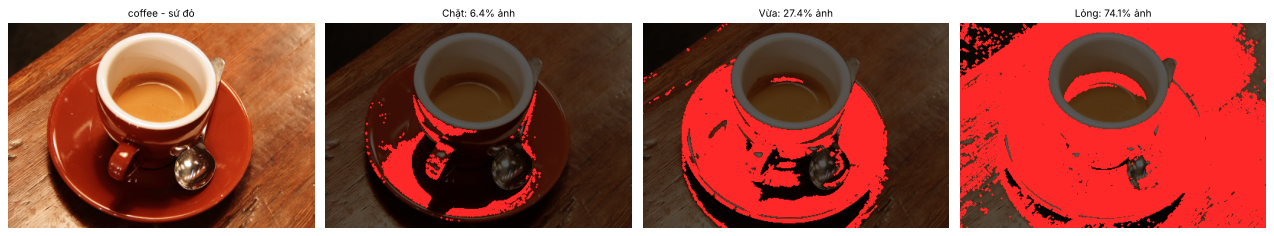

--- astronaut - bộ đồ cam ---
Chặt:  H∈[10,20], S≥0.70, V≥0.65     diện tích =   7.9% | IoU so với bộ 'vừa' = 0.406
Vừa:   H∈[5,25], S≥0.55, V≥0.40      diện tích =  19.5% | IoU so với bộ 'vừa' = 1.000
Lỏng:  H∈[0,40], S≥0.30, V≥0.20      diện tích =  25.8% | IoU so với bộ 'vừa' = 0.758


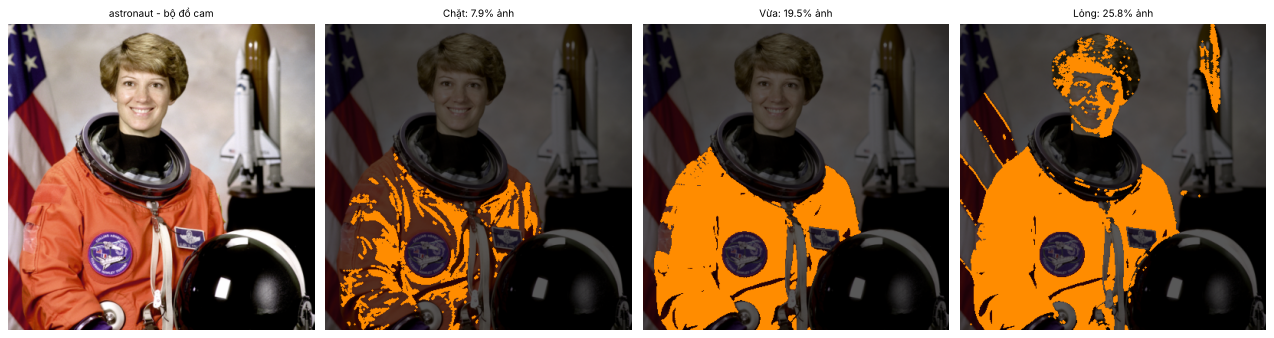

In [9]:
param_sets_coffee = {   # nhóm sứ đỏ
    "Chặt:  H∈[0,10], S≥0.85, V≥0.35": dict(h0=0, h1=10, smin=0.85, vmin=0.35),
    "Vừa:   H∈[0,16], S≥0.60, V≥0.15": dict(h0=0, h1=16, smin=0.60, vmin=0.15),
    "Lỏng:  H∈[0,26], S≥0.40, V≥0.08": dict(h0=0, h1=26, smin=0.40, vmin=0.08),
}
param_sets_astro = {    # nhóm bộ đồ cam
    "Chặt:  H∈[10,20], S≥0.70, V≥0.65": dict(h0=10, h1=20, smin=0.70, vmin=0.65),
    "Vừa:   H∈[5,25], S≥0.55, V≥0.40":  dict(h0=5, h1=25, smin=0.55, vmin=0.40),
    "Lỏng:  H∈[0,40], S≥0.30, V≥0.20":  dict(h0=0, h1=40, smin=0.30, vmin=0.20),
}
for nm, img, hsv, ps, col in [("coffee - sứ đỏ", coffee, hsv_c, param_sets_coffee, (255, 40, 40)),
                              ("astronaut - bộ đồ cam", astro, hsv_a, param_sets_astro, (255, 140, 0))]:
    imgs, tits = [img], [nm]
    print(f"--- {nm} ---")
    ref = m_hs(*hsv, **list(ps.values())[1])
    for pn, kw in ps.items():
        m = m_hs(*hsv, **kw)
        imgs.append(paint(img, [m], [col]))
        tits.append(f"{pn.split(':')[0]}: {100 * m.mean():.1f}% ảnh")
        print(f"{pn:36s} diện tích = {100 * m.mean():5.1f}% | IoU so với bộ 'vừa' = {iou(m, ref):.3f}")
    show(imgs, tits, ncols=4, cell=4.0, name="b1_params_" + nm.split()[0] + ".png")

**Nhận xét 1.3**
* `coffee` – sứ đỏ: bộ **chặt** chỉ còn 6,4% ảnh (IoU với bộ vừa 0,24): H ≤ 10° và S ≥ 0,85 loại hầu hết mặt đĩa/thân cốc, chỉ giữ vài mảng đỏ đậm -> *bỏ sót* nhiều. Bộ **vừa** (27,4%) phủ gần đủ đĩa và thân cốc. Bộ **lỏng** (74,1%, H ≤ 26°, S ≥ 0,4) tràn sang mặt bàn gỗ (Hue 22–30°) -> mất khả năng phân biệt hai nhóm, *nhiễm* nặng.
* `astronaut` – bộ đồ cam: bộ chặt (7,9%, IoU 0,41) chỉ lấy những nếp vải sáng nhất; bộ vừa (19,5%) lấy gần trọn bộ đồ; bộ lỏng (25,8%, IoU 0,76) bắt đầu lấn sang **da mặt, tóc, sọc cờ và thùng nhiên liệu nâu** của tàu con thoi (Hue 20–40°, S 0,3–0,5).
* **Rút ra:** độ rộng khoảng Hue quyết định mức nhiễm sang màu lân cận; `S_min` loại các điểm nhạt/trắng; `V_min` loại vùng quá tối (ở đó Hue không tin cậy). Thu hẹp ngưỡng tăng độ chính xác nhưng giảm độ phủ (trade-off precision/recall). Bộ "vừa" là cân bằng tốt nhất ở cả hai ảnh.